<a href="https://colab.research.google.com/github/animeshpaudel94-commits/CN6005/blob/main/Week2_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mean Squared Error: 33596915.85
R² Score: 0.78


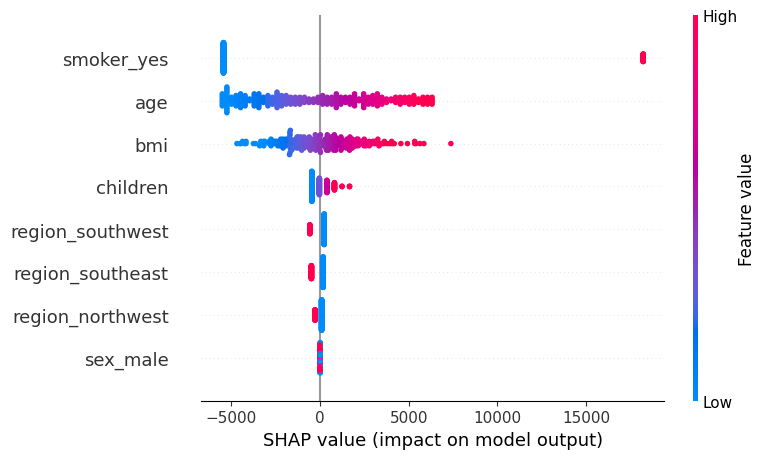

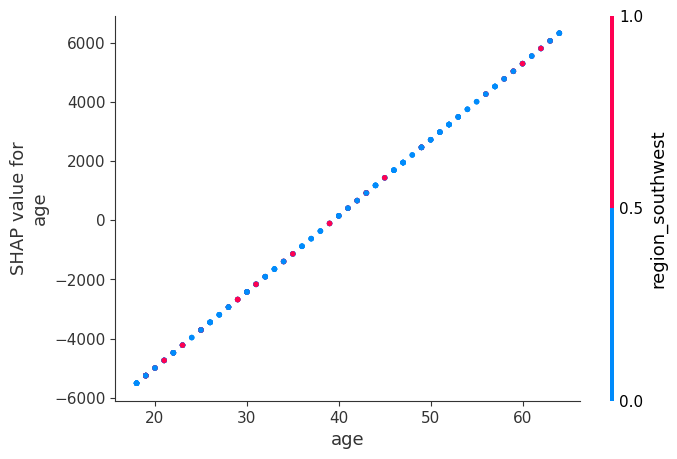

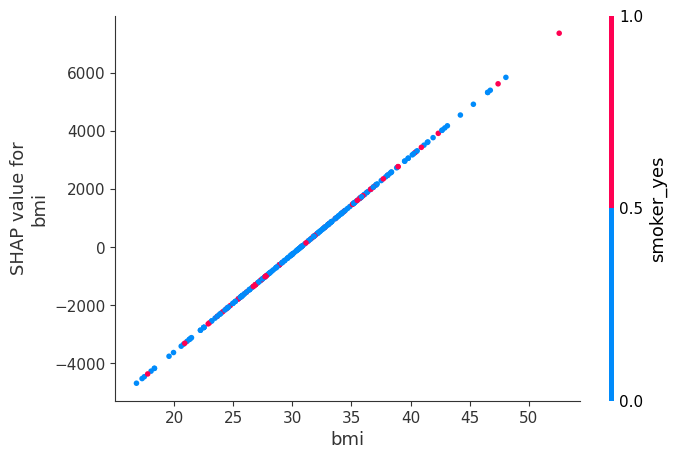

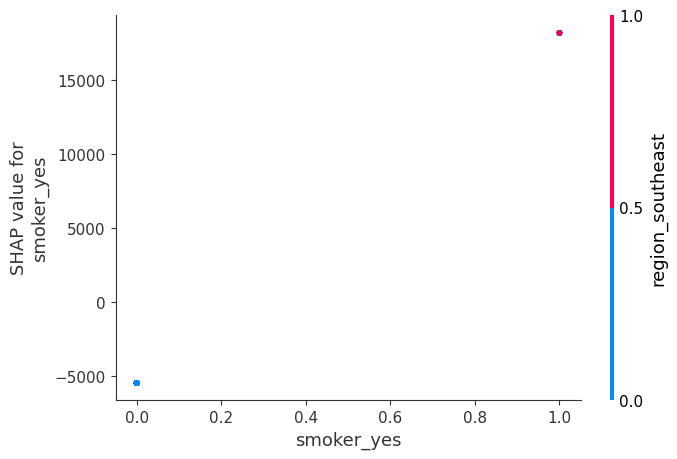

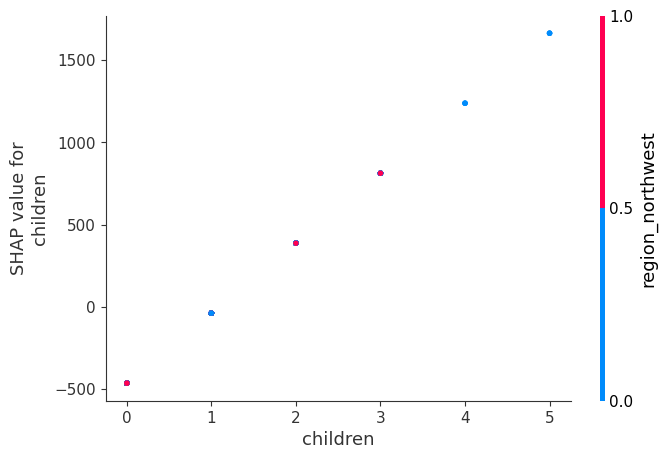

In [ ]:
import shap
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load the Medical Cost Dataset
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

# 2. Preprocess categorical variables (use dtype=int to prevent boolean type issues)
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)

# Define features (X) and target (y)
X = df.drop(columns=['charges'])
y = df['charges']

# 3. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

# 5. SHAP explanation using LinearExplainer (native and robust for linear models)
explainer = shap.LinearExplainer(model, X_train)
shap_values = explainer(X_test)

# SHAP summary plot
shap.summary_plot(shap_values, X_test)

# 6. Generate SHAP dependence plots for key features
selected_features = ['age', 'bmi', 'smoker_yes', 'children']
for feature in selected_features:
    if feature in X_test.columns:
        shap.dependence_plot(feature, shap_values.values, X_test, feature_names=X_test.columns)
        plt.savefig(f"shap_dependence_{feature}.png")
        plt.close()